# Notebook 08 — Analyse des erreurs

## Objectif
Comprendre dans quelles situations le meilleur modèle commet ses plus grandes erreurs : profils de patients difficiles, impact des valeurs manquantes, biais par cohorte ou par âge.

## Fichiers utilisés
- `data/X_train.csv` — variables explicatives
- `data/y_train.csv` — variable cible

## Résultat attendu
- Tableau des erreurs absolues triées
- Analyses par groupe (cohorte, présence de off/on, âge)

## Notebook suivant
`09_final_model.ipynb` — sélection et soumission du modèle final.

## 1. Imports

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import GroupKFold

## 2. Chargement des données

In [2]:
DATA_DIR = Path("../data")

X_train = pd.read_csv(DATA_DIR / "X_train.csv")
y_train = pd.read_csv(DATA_DIR / "y_train.csv")

visits = X_train.merge(
    y_train,
    on="Index",
    how="inner",
    validate="one_to_one",
)

assert len(visits) == len(X_train)
assert visits["target"].notna().all()

print(f"visits : {visits.shape} — OK")

visits : (44590, 14) — OK


## 3. Préparation des features (configuration avec feature engineering)

In [3]:
visits_fe = visits.copy()

# Feature 1 : ancienneté du diagnostic
visits_fe["years_since_diagnosis"] = visits_fe["age"] - visits_fe["age_at_diagnosis"]

# Feature 2 : indicateurs de valeurs manquantes
for col in ["on", "off", "ledd", "time_since_intake_on", "time_since_intake_off"]:
    visits_fe[f"{col}_missing"] = visits_fe[col].isna().astype(int)

# Feature 3 : écart OFF − ON
visits_fe["off_on_gap"] = visits_fe["off"] - visits_fe["on"]

feature_cols = [
    "sexM", "age_at_diagnosis", "age", "ledd",
    "time_since_intake_on", "time_since_intake_off", "on", "off",
    "years_since_diagnosis",
    "on_missing", "off_missing", "ledd_missing",
    "time_since_intake_on_missing", "time_since_intake_off_missing",
    "off_on_gap",
]

X = visits_fe[feature_cols]
y = visits_fe["target"]
groups = visits_fe["patient_id"]

print(f"X : {X.shape}")

X : (44590, 15)


## 4. Prédictions hors-échantillon via GroupKFold

Pour une analyse des erreurs sans biais, on génère les prédictions en validation croisée (chaque ligne est prédite quand son patient est en validation).

In [4]:
cv_splits = list(GroupKFold(n_splits=5).split(X, y, groups=groups))
oof_preds = np.zeros(len(y))

for train_idx, valid_idx in cv_splits:
    model = HistGradientBoostingRegressor(random_state=0)
    model.fit(X.iloc[train_idx], y.iloc[train_idx])
    oof_preds[valid_idx] = model.predict(X.iloc[valid_idx])

print(f"Prédictions OOF générées pour {len(oof_preds)} lignes")

Prédictions OOF générées pour 44590 lignes


## 5. Tableau des erreurs

In [5]:
errors = visits_fe[["Index", "patient_id", "target", "age", "cohort", "on", "off", "ledd"]].copy()
errors["prediction"]     = oof_preds
errors["error"]          = errors["prediction"] - errors["target"]
errors["absolute_error"] = errors["error"].abs()
errors = errors.sort_values("absolute_error", ascending=False)

print("Top 10 erreurs absolues :")
display(errors.head(10))

Top 10 erreurs absolues :


,Index,patient_id,target,age,cohort,on,off,ledd,prediction,error,absolute_error
32299,40065,AYWG6818,51.1,46.5,A,NaN,1.0,NaN,6.005983,-45.094017,45.094017
4682,5709,HNYR2211,83.9,52.9,A,23.0,NaN,472.0,41.468541,-42.431459,42.431459
38135,47372,ETNU0107,109.5,68.4,A,82.0,NaN,759.0,68.678498,-40.821502,40.821502
21921,27122,VQQV8870,45.1,45.5,B,NaN,0.0,NaN,5.331556,-39.768444,39.768444
38131,47368,ETNU0107,103.3,64.5,A,48.0,NaN,637.0,64.898936,-38.401064,38.401064
32693,40551,EWTV1012,73.4,75.1,A,13.0,NaN,1042.0,35.721604,-37.678396,37.678396
38134,47371,ETNU0107,108.3,67.7,A,59.0,NaN,717.0,70.807951,-37.492049,37.492049
37506,46588,XFCY5394,78.5,61.5,B,31.0,38.0,503.0,41.781020,-36.718980,36.718980
35536,44068,MWIG7755,74.1,48.7,A,21.0,NaN,584.0,37.425710,-36.674290,36.674290
18254,22550,LGUU2252,87.1,60.2,A,23.0,43.0,685.0,50.614483,-36.485517,36.485517


## 6. Question 1 — Le modèle se trompe-t-il davantage quand `off` est manquant ?

In [6]:
errors["off_missing"] = visits_fe["off"].isna().values
mae_off_missing = errors.loc[errors["off_missing"],  "absolute_error"].mean()
mae_off_present = errors.loc[~errors["off_missing"], "absolute_error"].mean()
print(f"MAE quand 'off' manquant : {mae_off_missing:.4f}  ({errors['off_missing'].sum()} lignes)")
print(f"MAE quand 'off' présent  : {mae_off_present:.4f}  ({(~errors['off_missing']).sum()} lignes)")

MAE quand 'off' manquant : 6.0149  (18913 lignes)
MAE quand 'off' présent  : 6.0139  (25677 lignes)


## 7. Question 2 — Les scores élevés sont-ils sous-estimés ?

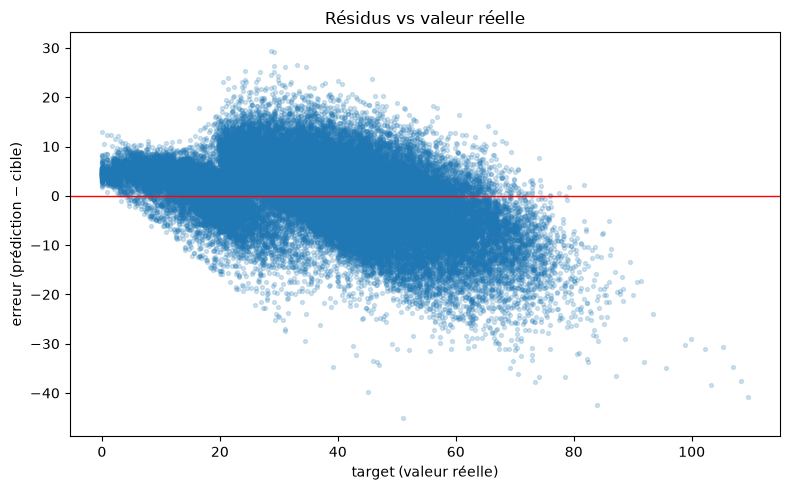

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(errors["target"], errors["error"], alpha=0.2, s=8)
ax.axhline(0, color="red", linewidth=1)
ax.set_xlabel("target (valeur réelle)")
ax.set_ylabel("erreur (prédiction − cible)")
ax.set_title("Résidus vs valeur réelle")
plt.tight_layout()
plt.show()

## 8. Question 3 — Certaines cohortes sont-elles plus difficiles ?

In [8]:
mae_by_cohort = (
    errors.groupby("cohort")["absolute_error"]
    .agg(["mean", "count"])
    .rename(columns={"mean": "MAE", "count": "N"})
    .sort_values("MAE", ascending=False)
    .round(4)
)
print("MAE par cohorte :")
display(mae_by_cohort)

MAE par cohorte :


,MAE,N
cohort,,
A,6.1097,39636
B,5.2514,4954


## 9. Question 4 — Les erreurs augmentent-elles avec l'âge ?

In [9]:
errors["age_bin"] = pd.cut(errors["age"], bins=6)
mae_by_age = (
    errors.groupby("age_bin", observed=True)["absolute_error"]
    .mean()
    .round(4)
)
print("MAE par tranche d'âge :")
print(mae_by_age)

MAE par tranche d'âge :
age_bin
(16.413, 30.967]    3.9341
(30.967, 45.433]    5.5499
(45.433, 59.9]      5.7538
(59.9, 74.367]      6.1526
(74.367, 88.833]    6.3758
(88.833, 103.3]     7.7558
Name: absolute_error, dtype: float64


## 10. Conclusion

Cette analyse identifie les profils de patients pour lesquels le modèle est le moins précis. Ces observations guident la sélection du modèle final et la préparation des features.

**Prochaine étape** : `09_final_model.ipynb` — sélection du modèle final, entraînement complet, soumission Kaggle.